In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv("Superstore_Cleaned_Data.csv", encoding="utf-8-sig")

print("Dataset loaded successfully!")
print("Rows and Columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and Columns: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,8877,US-2016-141264,13-08-2016,19-08-2016,Standard Class,CT-11995,Carol Triggs,Consumer,United States,Irving,...,75061,Central,OFF-AP-10002534,Office Supplies,Appliances,3.6 Cubic Foot Counter Height Office Refrigerator,58.924,1,0.8,-153.2024
1,9217,CA-2017-103765,24-11-2017,30-11-2017,Standard Class,JG-15310,Jason Gross,Corporate,United States,Odessa,...,79762,Central,OFF-AP-10002311,Office Supplies,Appliances,Holmes Replacement Filter for HEPA Air Cleaner...,13.762,1,0.8,-24.7716
2,5698,CA-2017-126123,14-10-2017,18-10-2017,Standard Class,AG-10765,Anthony Garverick,Home Office,United States,Chicago,...,60623,Central,OFF-BI-10004224,Office Supplies,Binders,Catalog Binders with Expanding Posts,13.456,1,0.8,-23.5480
3,6557,CA-2014-137092,20-10-2014,22-10-2014,Second Class,LS-16975,Lindsay Shagiari,Home Office,United States,Chicago,...,60653,Central,OFF-BI-10000632,Office Supplies,Binders,Satellite Sectional Post Binders,8.682,1,0.8,-14.7594
4,3394,CA-2014-105340,22-11-2014,25-11-2014,First Class,EH-14185,Evan Henry,Consumer,United States,Pasadena,...,77506,Central,OFF-BI-10001765,Office Supplies,Binders,Wilson Jones Heavy-Duty Casebound Ring Binders...,6.928,1,0.8,-11.0848


In [5]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18

In [6]:
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True)

print("Date columns converted successfully!")

print(df[["Order Date", "Ship Date"]].dtypes)

df[["Order Date", "Ship Date"]].head()

Date columns converted successfully!
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


,Order Date,Ship Date
0,2016-08-13,2016-08-19
1,2017-11-24,2017-11-30
2,2017-10-14,2017-10-18
3,2014-10-20,2014-10-22
4,2014-11-22,2014-11-25


In [7]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()

print("New date columns created successfully!")

df[["Order Date", "Year", "Month", "Month Name"]].head()

New date columns created successfully!


,Order Date,Year,Month,Month Name
0,2016-08-13,2016,8,August
1,2017-11-24,2017,11,November
2,2017-10-14,2017,10,October
3,2014-10-20,2014,10,October
4,2014-11-22,2014,11,November


In [8]:
yearly_analysis = df.groupby("Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2)

print("Year-wise Sales and Profit Analysis:")
yearly_analysis

Year-wise Sales and Profit Analysis:


,Total_Sales,Total_Profit
Year,,
2014,484247.50,49543.97
2015,470532.51,61618.60
2016,609205.60,81795.17
2017,733215.26,93439.27


In [9]:
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2).sort_values(by="Total_Sales", ascending=False)

print("Region-wise Sales and Profit Analysis:")
region_analysis

Region-wise Sales and Profit Analysis:


,Total_Sales,Total_Profit
Region,,
West,725457.82,108418.45
East,678781.24,91522.78
Central,501239.89,39706.36
South,391721.90,46749.43


In [10]:
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2).sort_values(by="Total_Sales", ascending=False)

print("Category-wise Sales and Profit Analysis:")
category_analysis

Category-wise Sales and Profit Analysis:


,Total_Sales,Total_Profit
Category,,
Technology,836154.03,145454.95
Furniture,741999.80,18451.27
Office Supplies,719047.03,122490.80


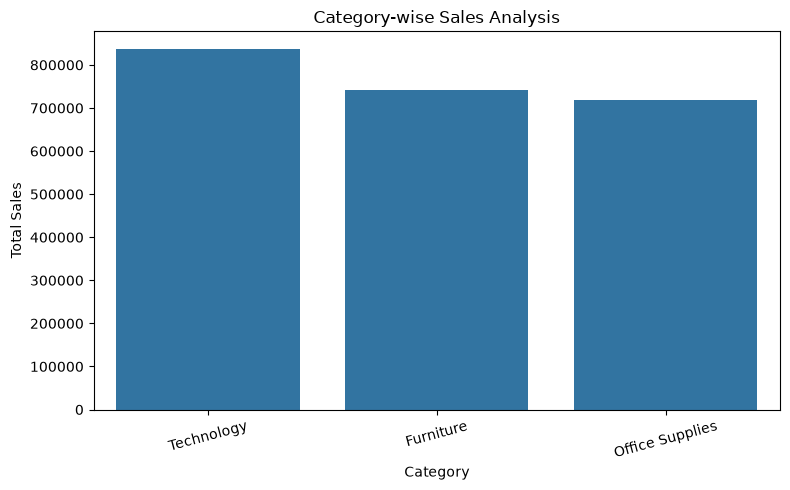

In [12]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_analysis.index,
    y=category_analysis["Total_Sales"]
)

plt.title("Category-wise Sales Analysis")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

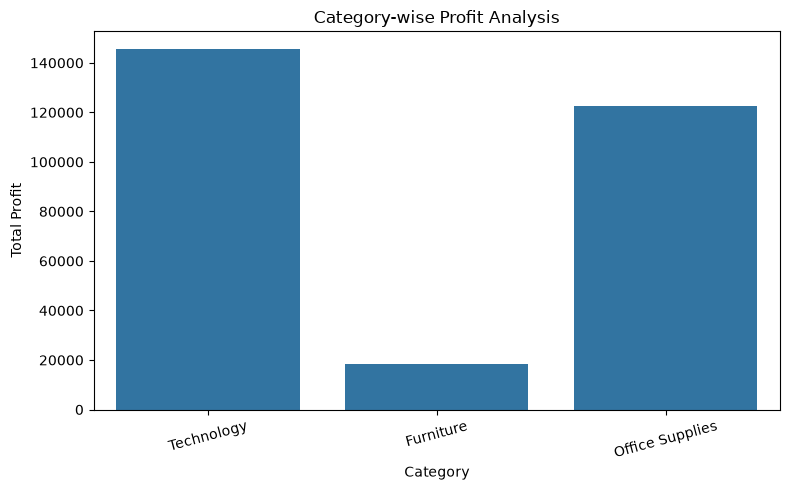

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_analysis.index,
    y=category_analysis["Total_Profit"]
)

plt.title("Category-wise Profit Analysis")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [14]:
monthly_analysis = df.groupby("Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2)

print("Month-wise Sales and Profit Analysis:")
monthly_analysis


Month-wise Sales and Profit Analysis:


,Total_Sales,Total_Profit
Month,,
1,94924.84,9134.45
2,59751.25,10294.61
3,205005.49,28594.69
4,137762.13,11587.44
5,155028.81,22411.31
6,152718.68,21285.80
7,147238.10,13832.66
8,159044.06,21776.94
9,307649.95,36857.48


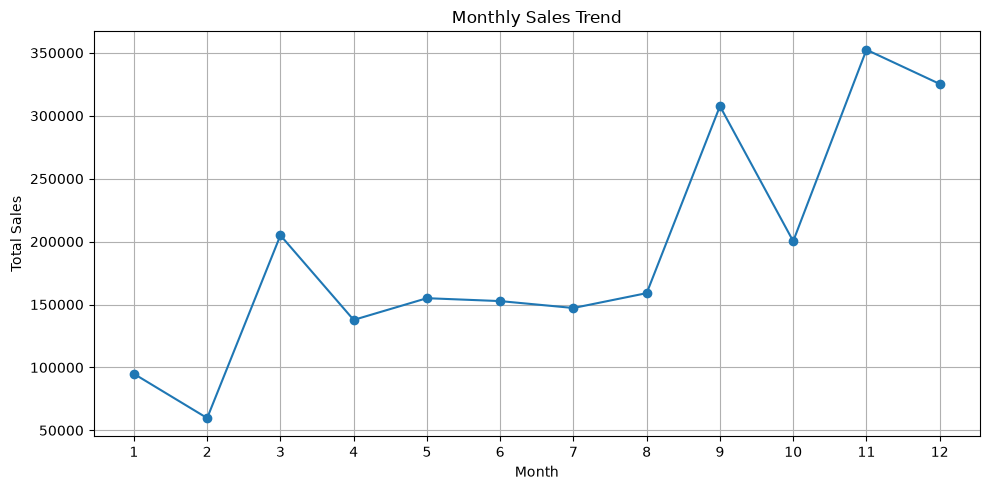

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_analysis.index,
    monthly_analysis["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
subcategory_analysis = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2).sort_values(by="Total_Sales", ascending=False)

print("Sub-Category Sales and Profit Analysis:")
subcategory_analysis

Sub-Category Sales and Profit Analysis:


,Total_Sales,Total_Profit
Sub-Category,,
Phones,330007.05,44515.73
Chairs,328449.10,26590.17
Storage,223843.61,21278.83
Tables,206965.53,-17725.48
Binders,203412.73,30221.76
Machines,189238.63,3384.76
Accessories,167380.32,41936.64
Copiers,149528.03,55617.82
Bookcases,114880.00,-3472.56


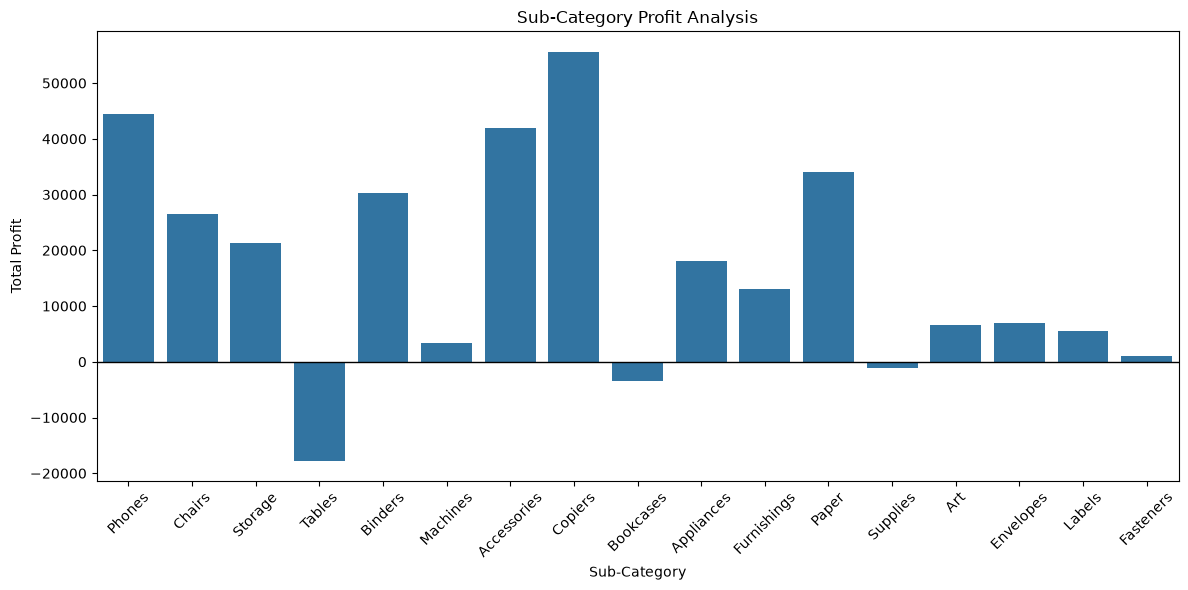

In [17]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=subcategory_analysis.index,
    y=subcategory_analysis["Total_Profit"]
)

plt.title("Sub-Category Profit Analysis")
plt.xlabel("Sub-Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

In [18]:
segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).round(2).sort_values(by="Total_Sales", ascending=False)

print("Segment-wise Sales and Profit Analysis:")
segment_analysis

Segment-wise Sales and Profit Analysis:


,Total_Sales,Total_Profit,Total_Orders
Segment,,,
Consumer,1161401.34,134119.21,2586
Corporate,706146.37,91979.13,1514
Home Office,429653.15,60298.68,909


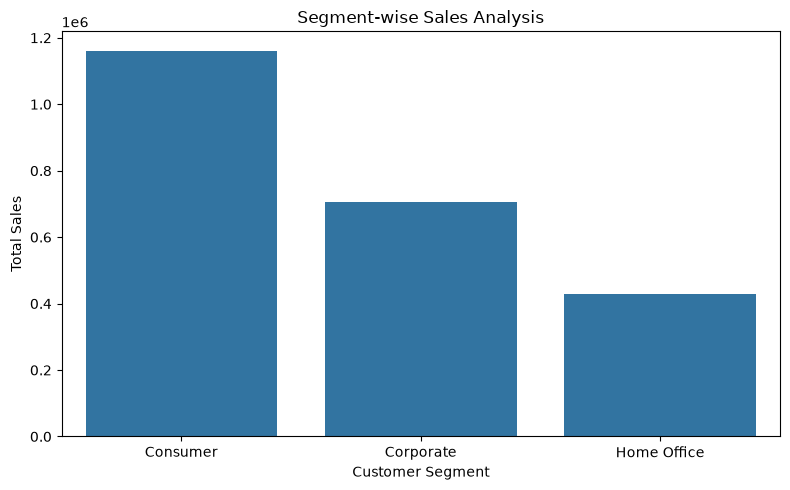

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=segment_analysis.index,
    y=segment_analysis["Total_Sales"]
)

plt.title("Segment-wise Sales Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [20]:
shipmode_analysis = df.groupby("Ship Mode").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).round(2).sort_values(by="Total_Sales", ascending=False)

print("Ship Mode Sales and Profit Analysis:")
shipmode_analysis

Ship Mode Sales and Profit Analysis:


,Total_Sales,Total_Profit,Total_Orders
Ship Mode,,,
Standard Class,1358215.74,164088.79,2994
Second Class,459193.57,57446.64,964
First Class,351428.42,48969.84,787
Same Day,128363.12,15891.76,264


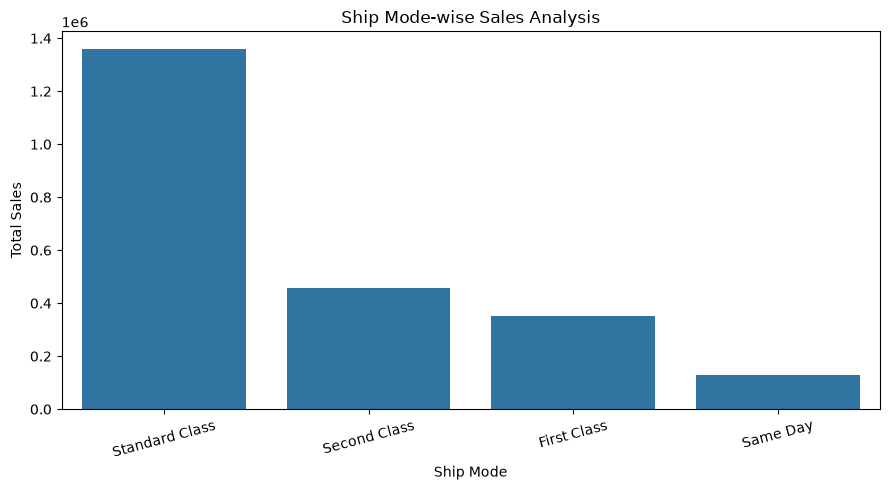

In [21]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=shipmode_analysis.index,
    y=shipmode_analysis["Total_Sales"]
)

plt.title("Ship Mode-wise Sales Analysis")
plt.xlabel("Ship Mode")
plt.ylabel("Total Sales")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [22]:
top_products = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2).sort_values(
    by="Total_Sales", ascending=False
).head(10)

print("Top 10 Products by Sales:")
top_products

Top 10 Products by Sales:


,Total_Sales,Total_Profit
Product Name,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08
HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00
GBC DocuBind TL300 Electric Binding System,19823.48,2233.51
GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17


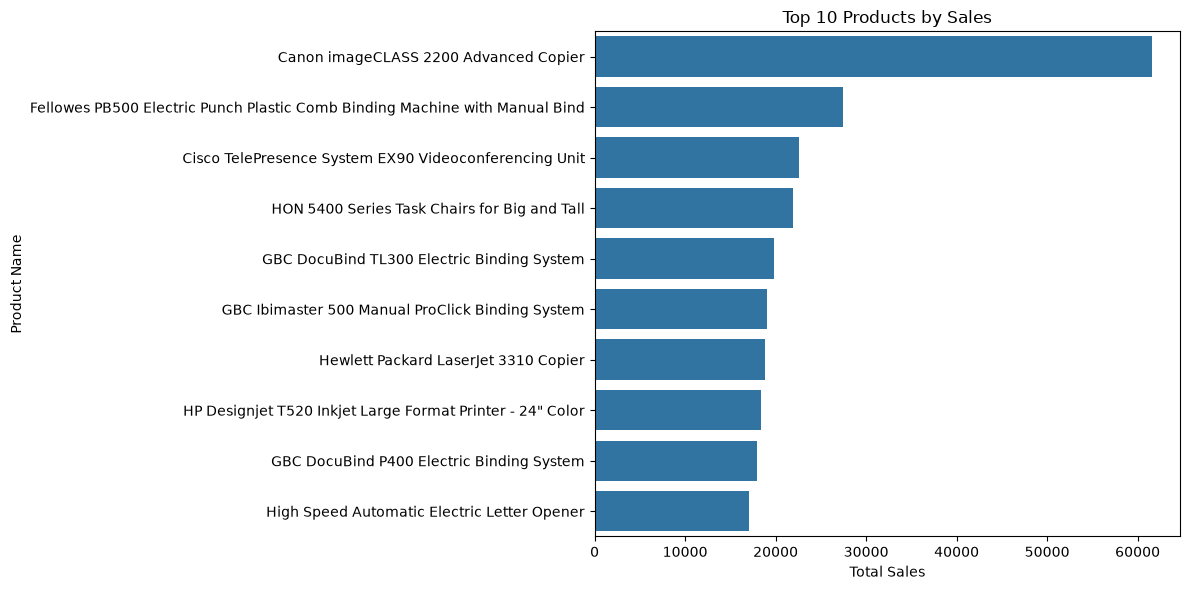

In [23]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_products["Total_Sales"],
    y=top_products.index
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

In [24]:
top_customers = df.groupby("Customer Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2).sort_values(
    by="Total_Sales", ascending=False
).head(10)

print("Top 10 Customers by Sales:")
top_customers

Top 10 Customers by Sales:


,Total_Sales,Total_Profit
Customer Name,,
Sean Miller,25043.05,-1980.74
Tamara Chand,19052.22,8981.32
Raymond Buch,15117.34,6976.10
Tom Ashbrook,14595.62,4703.79
Adrian Barton,14473.57,5444.81
Ken Lonsdale,14175.23,806.85
Sanjit Chand,14142.33,5757.41
Hunter Lopez,12873.30,5622.43
Sanjit Engle,12209.44,2650.68


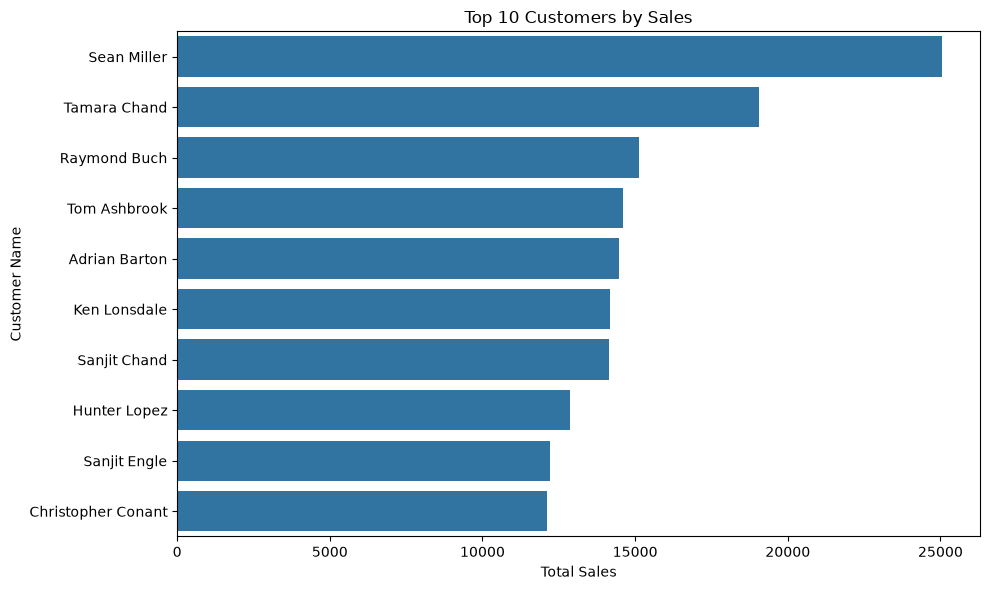

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_customers["Total_Sales"],
    y=top_customers.index
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")
plt.tight_layout()
plt.show()

In [26]:
discount_analysis = df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2)

print("Discount vs Profit Analysis:")
discount_analysis

Discount vs Profit Analysis:


,Total_Sales,Total_Profit
Discount,,
0.00,1087908.47,320987.60
0.10,54369.35,9029.18
0.15,27558.52,1418.99
0.20,764594.37,90337.31
0.30,103226.66,-10369.28
0.32,14493.46,-2391.14
0.40,116417.78,-23057.05
0.45,5484.97,-2493.11
0.50,58918.54,-20506.43


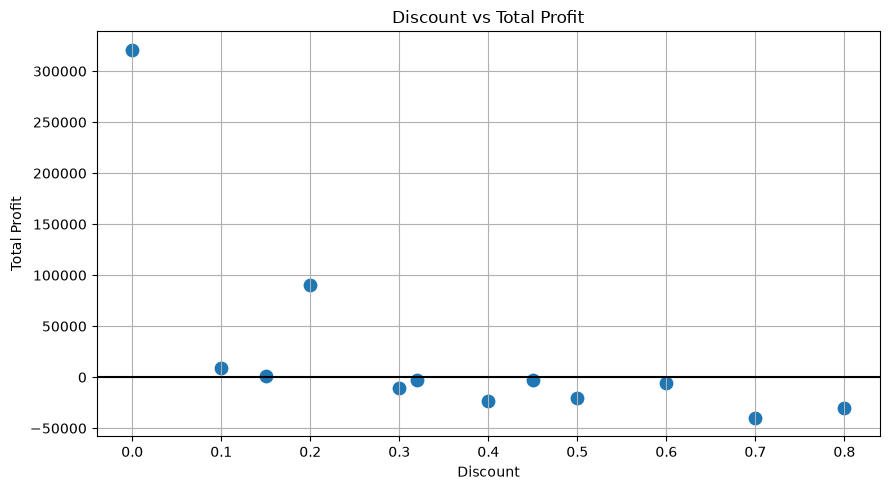

In [27]:
plt.figure(figsize=(9, 5))

plt.scatter(
    discount_analysis.index,
    discount_analysis["Total_Profit"],
    s=80
)

plt.title("Discount vs Total Profit")
plt.xlabel("Discount")
plt.ylabel("Total Profit")
plt.axhline(0, color="black")
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
correlation = df[[
    "Sales",
    "Profit",
    "Quantity",
    "Discount"
]].corr().round(2)

print("Correlation Analysis:")
correlation

Correlation Analysis:


,Sales,Profit,Quantity,Discount
Sales,1.00,0.48,0.20,-0.03
Profit,0.48,1.00,0.07,-0.22
Quantity,0.20,0.07,1.00,0.01
Discount,-0.03,-0.22,0.01,1.00


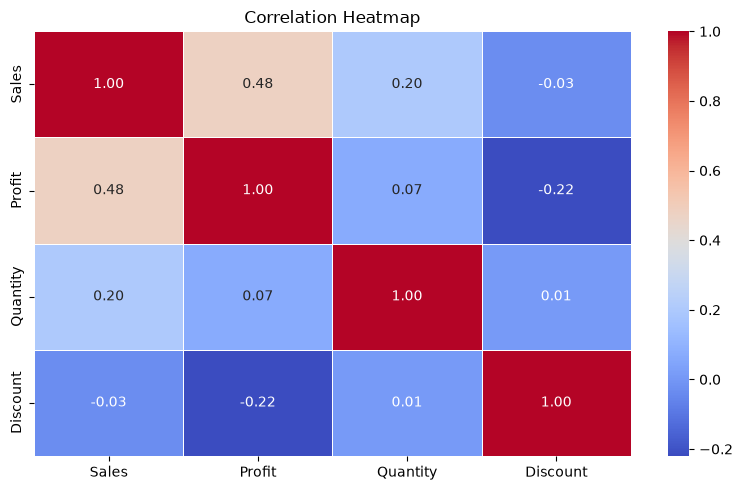

In [29]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()